# Vinculum 01 · Which fundamentals are available, and how they behave

`Vinculum.fundamentals()` puts SEC EDGAR numbers next to prices: one row per security and month
end (or day), with each item **as it was known that day**. The chain is:

1. **EDGAR** keeps every XBRL fact of every 10-K/10-Q/20-F/40-F with its filing date.
2. **Items** (`edgar_cortical_node.CONCEPTS`) turn hundreds of tags into 31 named fields.
3. **vinculum** attaches them to securities through the checked CIK of each security and day,
   never by ticker, and adds market cap.

This notebook covers what the fields are, how complete they are, and where they mislead.
Ratios built from them are in `02_ratios.ipynb`.

1. the catalogue
2. one company, every field
3. coverage
4. which XBRL tag supplied the value
5. point in time: when a number becomes usable
6. first-filed vs restated values
7. reporting currencies
8. pitfalls

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from edgar_cortical_node import CONCEPTS, EdgarStore
from massive_subspace_stream import Store
from subspace_probe import style, timed
from vinculum import Vinculum

style()
pl.Config.set_tbl_rows(35)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_fmt_str_lengths(70)
v = Vinculum()
edgar = EdgarStore()
massive = Store()
print(f"vinculum built through {v.status()['through']}")

vinculum built through 2026-11-03


## 1 · The catalogue

Each item maps to several XBRL tags in priority order, so a company that changed tags (most
did in 2018, when revenue moved to `RevenueFromContractWithCustomer...`) keeps one series.
US filers use `us-gaap` tags; foreign filers using IFRS use `ifrs-full`.

In [2]:
GROUPS = {
    "income": ["revenue", "cost_of_revenue", "gross_profit", "sga", "rnd", "depreciation_amortization",
               "operating_income", "interest_expense", "pretax_income", "income_tax", "net_income",
               "eps_basic", "eps_diluted"],
    "cash flow": ["operating_cash_flow", "capex", "dividends_paid", "buybacks", "stock_comp"],
    "balance sheet": ["assets", "current_assets", "cash", "receivables", "inventory", "goodwill",
                      "liabilities", "current_liabilities", "debt_current", "short_term_borrowings",
                      "long_term_debt", "equity"],
    "10-K cover": ["public_float"],
}
STATEMENT = {i: g for g, items in GROUPS.items() for i in items}
ITEMS = [i for items in GROUPS.values() for i in items]
assert sorted(ITEMS) == sorted(CONCEPTS)
catalogue = pl.DataFrame(
    [(k, STATEMENT[k], CONCEPTS[k].kind, CONCEPTS[k].unit, len(CONCEPTS[k].tags), CONCEPTS[k].description)
     for k in ITEMS],
    schema=["item", "statement", "kind", "unit", "tags", "description"], orient="row")
catalogue

item,statement,kind,unit,tags,description
str,str,str,str,i64,str
"""revenue""","""income""","""flow""","""currency""",13,"""Total revenue. Banks without a total use net revenue, then interest an…"
"""cost_of_revenue""","""income""","""flow""","""currency""",3,"""Cost of revenue / cost of goods and services sold"""
"""gross_profit""","""income""","""flow""","""currency""",2,"""Gross profit"""
"""sga""","""income""","""flow""","""currency""",2,"""Selling, general and administrative expense (only where reported as on…"
"""rnd""","""income""","""flow""","""currency""",3,"""Research and development expense"""
"""depreciation_amortization""","""income""","""flow""","""currency""",5,"""Depreciation, depletion and amortization (depreciation alone is not us…"
"""operating_income""","""income""","""flow""","""currency""",2,"""Operating income"""
"""interest_expense""","""income""","""flow""","""currency""",5,"""Interest expense (for banks this includes interest on deposits; IFRS f…"
"""pretax_income""","""income""","""flow""","""currency""",3,"""Income from continuing operations before income taxes"""


In [3]:
print("revenue tags, first match wins:")
for t in CONCEPTS["revenue"].tags:
    print("  ", t)

revenue tags, first match wins:
   us-gaap:Revenues
   us-gaap:RevenueFromContractWithCustomerExcludingAssessedTax
   us-gaap:RevenueFromContractWithCustomerIncludingAssessedTax
   us-gaap:SalesRevenueNet
   us-gaap:SalesRevenueGoodsNet
   us-gaap:SalesRevenueServicesNet
   ifrs-full:Revenue
   ifrs-full:RevenueFromContractsWithCustomers
   us-gaap:RevenuesNetOfInterestExpense
   us-gaap:OperatingLeaseLeaseIncome
   us-gaap:LeaseIncome
   us-gaap:PremiumsEarnedNet
   us-gaap:InterestAndDividendIncomeOperating


The `kind` decides what a panel cell holds:

| kind | items | value in `fundamentals()` | usable from |
|---|---|---|---|
| flow | income statement and cash flow items | trailing twelve months: the last four quarters (Q4 derived as annual minus nine months) | the day after the latest of the four was filed |
| instant | balance sheet items, public_float | the latest balance-sheet value | the day after filing |
| per_share | eps_basic, eps_diluted | trailing twelve months **in the security's share units that day** (the annual figure at fiscal year ends) | the day after the latest filing |

Any value whose period ended more than 400 days before the row's date is set to missing, so a
company that stopped filing drops out instead of carrying old numbers forward. `public_float`
is the exception: it is measured mid-year and filed months later, so it ages from its filing.

## 2 · One company, every field

The whole panel, all 31 items at month ends since 2010:

In [4]:
with timed("fundamentals: 31 items, month ends 2010-2026"):
    f = v.fundamentals(ITEMS, start="2010-01-01")
print(f"{f.height:,} rows x {f.width} columns, {f['security_id'].n_unique():,} securities, "
      f"{f['cik'].n_unique():,} companies")
print(f.columns)

fundamentals: 31 items, month ends 2010-2026: 4.34 s
1,048,019 rows x 43 columns, 13,869 securities, 11,831 companies
['date', 'security_id', 'ticker', 'cik', 'close', 'market_cap', 'issuer_market_cap', 'revenue', 'cost_of_revenue', 'gross_profit', 'sga', 'rnd', 'depreciation_amortization', 'operating_income', 'interest_expense', 'pretax_income', 'income_tax', 'net_income', 'eps_basic', 'eps_diluted', 'operating_cash_flow', 'capex', 'dividends_paid', 'buybacks', 'stock_comp', 'assets', 'current_assets', 'cash', 'receivables', 'inventory', 'goodwill', 'liabilities', 'current_liabilities', 'debt_current', 'short_term_borrowings', 'long_term_debt', 'equity', 'public_float', 'currency', 'earnings_yield', 'book_to_market', 'sales_to_price', 'cash_flow_yield']


In [5]:
last = f["date"].max()
names = ["AAPL", "WMT", "JPM", "NVO"]
snap = f.filter((pl.col("date") == last) & pl.col("ticker").is_in(names))
money = [i for i in ITEMS if CONCEPTS[i].unit == "currency"]
show = snap.to_pandas().set_index("ticker").loc[names, ITEMS].T.astype(float)
show.loc[money] = show.loc[money] / 1e9
show.index = [f"{i} (bn)" if i in money else i for i in ITEMS]
print(f"as known on {last}; currency:", dict(zip(snap["ticker"], snap["currency"], strict=True)))
show.round(2)

as known on 2026-11-03; currency: {'AAPL': 'USD', 'NVO': 'DKK', 'WMT': 'USD', 'JPM': 'USD'}


ticker,AAPL,WMT,JPM,NVO
revenue (bn),466.82,735.84,199.41,309.06
cost_of_revenue (bn),239.70,550.18,NaN,58.79
gross_profit (bn),227.12,NaN,NaN,250.28
sga (bn),29.36,153.38,NaN,NaN
rnd (bn),42.90,NaN,NaN,52.04
depreciation_amortization (bn),13.10,15.09,9.26,14.67
operating_income (bn),154.86,32.28,NaN,127.66
interest_expense (bn),NaN,1.86,NaN,6.78
pretax_income (bn),155.91,29.32,83.90,130.54
income_tax (bn),26.98,6.82,18.83,28.11


Things to notice:
- **JPMorgan** has no gross profit, operating income or capex: a bank's income statement has
  no such lines, and its "revenue" is net revenue. Its operating cash flow swings with trading
  assets and can be hugely negative. Industrial ratios don't transfer to banks.
- **Novo Nordisk** reports in Danish kroner (`currency` = DKK): the values are there, but
  anything divided by a USD market cap is not (section 7).
- **Walmart** has no R&D line, and **Apple** reports no goodwill and no separate interest
  expense since 2024: a missing expense line is usually one the company doesn't present.
- `public_float` is missing for Novo Nordisk: foreign filers (20-F) don't report it.

## 3 · Coverage

Share of companies (primary class, with a market cap) that have each item, at the end of 2025.
Weighted by market cap, coverage is near complete for the core items; equally weighted it
shows which items small companies don't report.

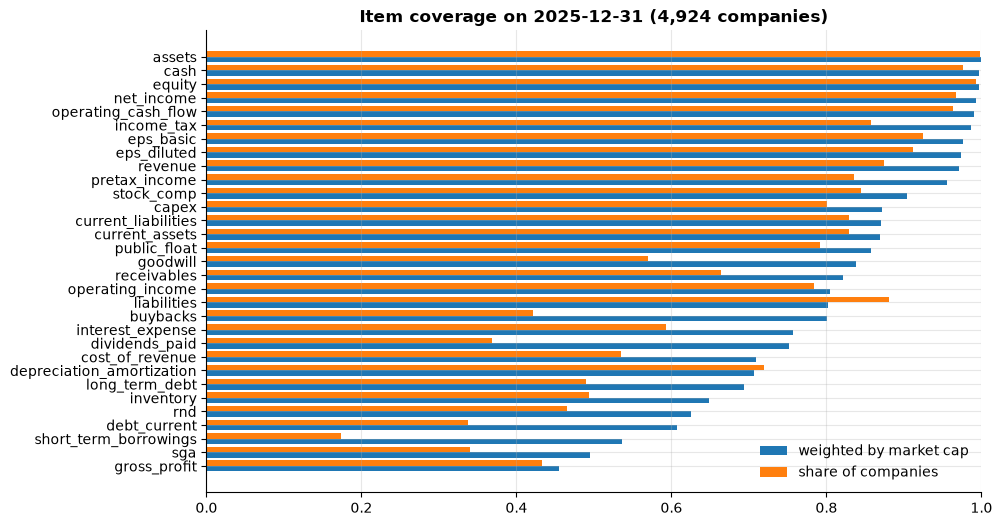

In [6]:
ref = f.filter(pl.col("date").dt.year() == 2025)["date"].max()
d = f.filter((pl.col("date") == ref) & pl.col("issuer_market_cap").is_not_null())
w = d["issuer_market_cap"]
cov = pl.DataFrame({
    "item": ITEMS,
    "by_market_cap": [float((d[i].is_not_null() * w).sum() / w.sum()) for i in ITEMS],
    "by_company": [float(d[i].is_not_null().mean()) for i in ITEMS],
}).sort("by_market_cap")
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(cov.height)
ax.barh(y - 0.2, cov["by_market_cap"], height=0.4, label="weighted by market cap")
ax.barh(y + 0.2, cov["by_company"], height=0.4, label="share of companies")
ax.set_yticks(y, cov["item"])
ax.set_xlim(0, 1)
ax.set_title(f"Item coverage on {ref} ({d.height:,} companies)")
ax.legend(loc="lower right")
plt.show()

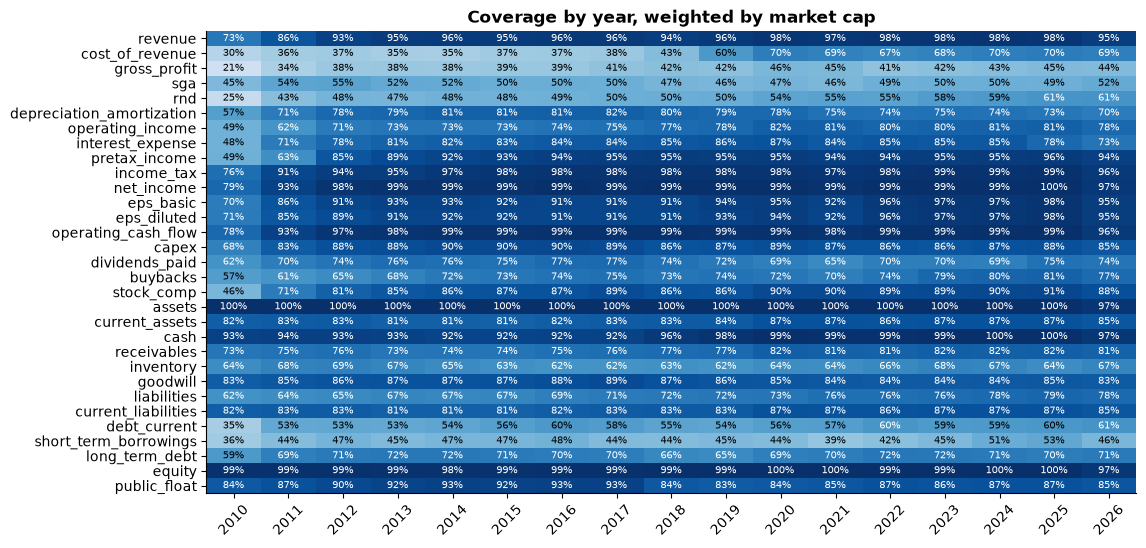

In [7]:
yr = pl.col("date").dt.year().alias("year")
by_year = (f.filter(pl.col("issuer_market_cap").is_not_null()).group_by(yr)
           .agg([((pl.col(i).is_not_null().cast(pl.Float64) * pl.col("issuer_market_cap")).sum()
                  / pl.col("issuer_market_cap").sum()).alias(i) for i in ITEMS])
           .sort("year"))
grid = by_year.select(ITEMS).to_numpy().T
fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(grid, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(ITEMS)), ITEMS)
ax.set_xticks(range(by_year.height), by_year["year"].to_list(), rotation=45)
for (r, c), val in np.ndenumerate(grid):
    ax.text(c, r, f"{val:.0%}", ha="center", va="center", fontsize=7,
            color="white" if val > 0.6 else "black")
ax.grid(False)
ax.set_title("Coverage by year, weighted by market cap")
plt.show()

- **Near complete** (95%+ of market cap): revenue, net income, EPS, operating cash flow,
  assets, equity, cash.
- **Partial by nature**: `gross_profit` (banks, insurers, utilities and many service companies
  present no gross-profit line), `operating_income` (banks), `long_term_debt` (companies with
  no debt, and others that report it only split into current/noncurrent parts under other
  tags), `liabilities` (many balance sheets show no total liabilities line).
- **Missing means "not reported", which is not always zero**: `dividends_paid` and `buybacks`
  cover about half the companies because many small companies return no cash. Expense lines
  depend on presentation: `sga` only where one SG&A line is reported (Amazon splits it into
  fulfillment, marketing and G&A, so it has none), `cost_of_revenue` not for banks or many
  service companies, `current_assets` not for banks and insurers. Each item falls back over
  several tags (capex: Amazon's `PaymentsToAcquireProductiveAssets`; dividends: Pfizer's
  `PaymentsOfOrdinaryDividends`), but a number filed under a tag outside the catalogue is still
  missing.
- 2010 is thin because small companies only started XBRL in 2011.

## 4 · Which XBRL tag supplied the value

Every value in `EdgarStore.series()` keeps its `tag`. Annual revenue of every company in the
panel, by the tag that supplied it: the 2018 move to ASC 606 shows as a switch from
`Revenues`/`SalesRevenueNet` to `RevenueFromContractWithCustomer...`. Without the priority list,
a single-tag series would break for most companies that year.

revenue series for 11,830 companies: 0.01 s


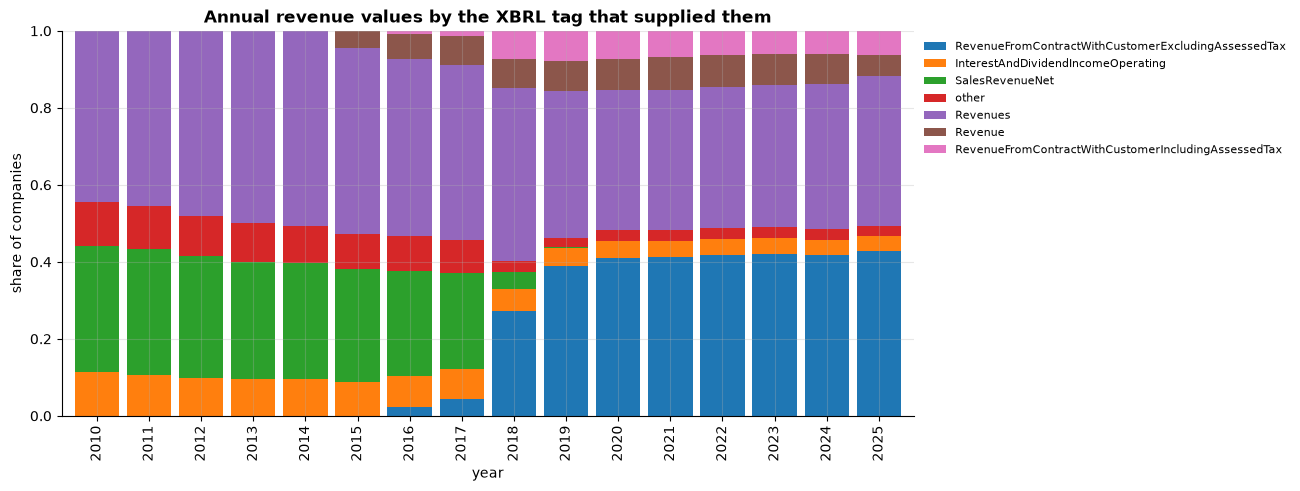

In [8]:
ciks = f["cik"].drop_nulls().unique().to_list()
with timed(f"revenue series for {len(ciks):,} companies"):
    rev = edgar.series(["revenue"], ciks)
ann = rev.filter((pl.col("period") == "annual") & (pl.col("source") == "reported")
                 & pl.col("end").dt.year().is_between(2010, 2025))
top_tags = ann["tag"].value_counts().sort("count", descending=True).head(6)["tag"].to_list()
mix = (ann.with_columns(pl.when(pl.col("tag").is_in(top_tags)).then(pl.col("tag").str.split(":").list.last())
                        .otherwise(pl.lit("other")).alias("tag"), pl.col("end").dt.year().alias("year"))
       .group_by("year", "tag").len()
       .with_columns((pl.col("len") / pl.col("len").sum().over("year")).alias("share"))
       .pivot(on="tag", index="year", values="share").sort("year").fill_null(0))
ax = mix.to_pandas().set_index("year").plot.bar(stacked=True, figsize=(11, 5), width=0.85)
ax.set_title("Annual revenue values by the XBRL tag that supplied them")
ax.set_ylabel("share of companies")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 5 · Point in time: when a number becomes usable

A value is usable from the day after its filing, never from its period end. The gap is the
filing lag: about 40 days for a 10-Q, 60-90 days for a 10-K (deadlines depend on filer size),
longer for foreign filers. TTM flows wait for the latest of their four quarters. The long
tail (p90 above a year) is periods first seen as comparison columns of a later filing: the
years before a company's first XBRL filing, or before it went public.

shape: (2, 4)
┌─────────┬────────┬─────────────┬──────────┐
│ period  ┆ len    ┆ median_days ┆ p90_days │
│ ---     ┆ ---    ┆ ---         ┆ ---      │
│ str     ┆ u32    ┆ f64         ┆ f64      │
╞═════════╪════════╪═════════════╪══════════╡
│ annual  ┆ 96457  ┆ 74.0        ┆ 473.0    │
│ quarter ┆ 277069 ┆ 41.0        ┆ 395.0    │
└─────────┴────────┴─────────────┴──────────┘


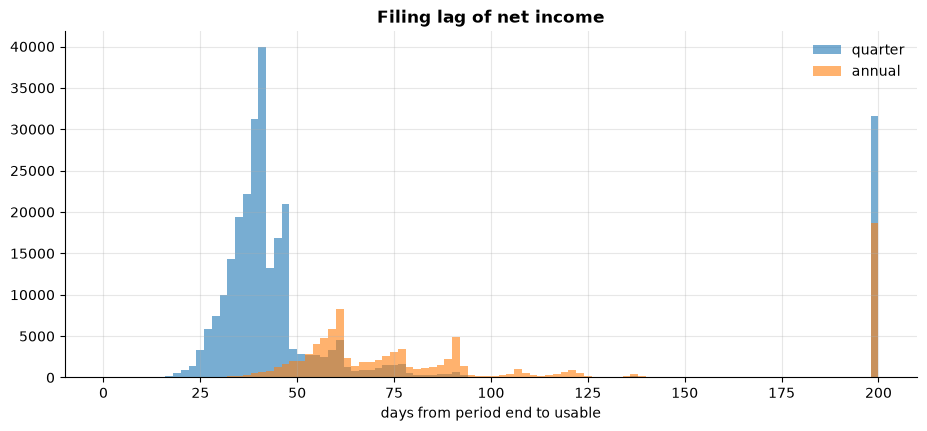

In [9]:
ni = edgar.series(["net_income"], ciks).filter(pl.col("source") == "reported")
lag = (ni.filter(pl.col("period").is_in(["quarter", "annual"]))
       .with_columns((pl.col("available_from") - pl.col("end")).dt.total_days().alias("lag_days")))
print(lag.group_by("period").agg(pl.len(), pl.col("lag_days").median().alias("median_days"),
                                 pl.col("lag_days").quantile(0.9).alias("p90_days")))
fig, ax = plt.subplots()
for p in ["quarter", "annual"]:
    ax.hist(lag.filter(pl.col("period") == p)["lag_days"].clip(0, 200), bins=100, alpha=0.6, label=p)
ax.set_xlabel("days from period end to usable")
ax.set_title("Filing lag of net income")
ax.legend()
plt.show()

What that means for a panel: Apple's TTM revenue and net income, daily, against the period
end each value belongs to. The panel steps up the day after each filing, roughly five weeks
after the quarter closed.

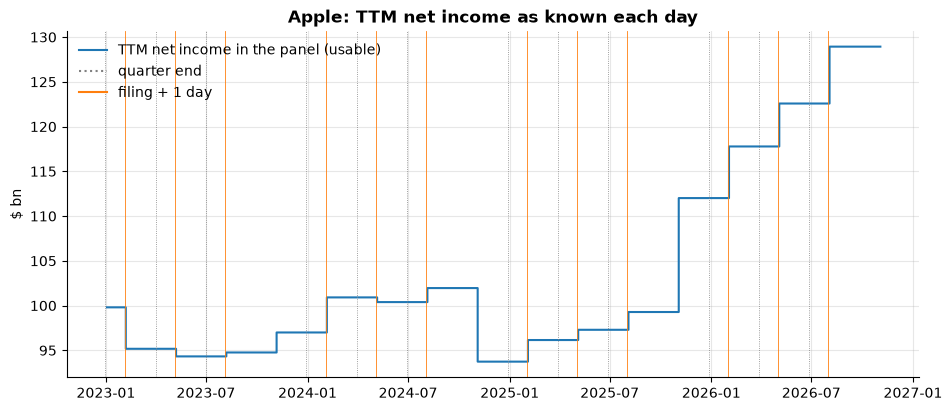

In [10]:
a = v.fundamentals(["revenue", "net_income"], start="2023-01-01", tickers="AAPL", freq="1d", ratios=False)
q = ni.filter((pl.col("cik") == "0000320193") & (pl.col("period") == "quarter")
              & (pl.col("end") >= date(2022, 12, 1)))
fig, ax = plt.subplots()
ax.step(a["date"], a["net_income"] / 1e9, where="post", label="TTM net income in the panel (usable)")
for row in q.iter_rows(named=True):
    ax.axvline(row["end"], color="grey", lw=0.6, ls=":")
    ax.axvline(row["available_from"], color="tab:orange", lw=0.6)
ax.plot([], [], color="grey", ls=":", label="quarter end")
ax.plot([], [], color="tab:orange", label="filing + 1 day")
ax.set_ylabel("$ bn")
ax.set_title("Apple: TTM net income as known each day")
ax.legend()
plt.show()

## 6 · First-filed vs restated values

The default `policy="first"` gives each period's value as first filed. Companies restate:
later filings carry new numbers for old periods (mergers, accounting changes, errors).
`policy="latest"` returns the latest figure, which is what most databases show, and it looks
ahead. How often do they differ for the large and mid caps?

In [11]:
top = v.ranks(ref).head(1000)["cik"].drop_nulls().unique().to_list()
key = ["cik", "item", "unit", "period", "start", "end"]
pick = ["revenue", "net_income", "equity", "assets"]


def reported(policy):
    s = edgar.series(pick, top, policy=policy).filter(pl.col("source") == "reported")
    return s.with_columns(pl.col("start").fill_null(pl.col("end")))


first = reported("first").select(*key, "value", "filed")
latest = reported("latest").select(*key, pl.col("value").alias("restated"), pl.col("filed").alias("restated_filed"))
j = first.join(latest, on=key).with_columns(
    ((pl.col("restated") / pl.col("value") - 1).abs()).alias("change"))
j.group_by("item").agg(pl.len().alias("values"), (pl.col("change") > 0.005).mean().alias("restated_>0.5%"),
                       (pl.col("change") > 0.05).mean().alias("restated_>5%")).sort("item")

item,values,restated_>0.5%,restated_>5%
str,u32,f64,f64
"""assets""",51209,0.017419,0.00371
"""equity""",53559,0.227375,0.094345
"""net_income""",58630,0.076036,0.039229
"""revenue""",57333,0.092774,0.057035


In [12]:
names_ = edgar.profiles(top).select("cik", "name")
(j.filter((pl.col("item") == "net_income") & (pl.col("period") == "annual") & (pl.col("unit") == "USD")
          & (pl.col("value").abs() > 1e9) & (pl.col("restated") != 0)
          & (pl.col("end").dt.year() >= 2015))
 .sort("change", descending=True).head(8).join(names_, on="cik")
 .select("name", "end", (pl.col("value") / 1e9).round(2).alias("first_bn"), "filed",
         (pl.col("restated") / 1e9).round(2).alias("restated_bn"), "restated_filed"))

name,end,first_bn,filed,restated_bn,restated_filed
str,date,f64,date,f64,date
"""LINCOLN NATIONAL CORP""",2021-12-31,1.4,2022-02-17,3.78,2026-04-16
"""LINCOLN NATIONAL CORP""",2022-12-31,-2.23,2023-02-16,1.36,2026-04-16
"""PAYCHEX INC""",2024-05-31,1.69,2024-07-11,0.0,2026-09-04
"""PG&E Corp""",2022-12-31,1.8,2023-02-23,0.0,2026-04-09
"""Arista Networks, Inc.""",2022-12-31,1.35,2023-02-14,0.0,2026-04-16
"""Arista Networks, Inc.""",2023-12-31,2.09,2024-02-13,0.0,2026-04-16
"""Arista Networks, Inc.""",2025-12-31,3.51,2026-02-17,0.0,2026-04-16
"""Arista Networks, Inc.""",2024-12-31,2.85,2025-02-19,0.0,2026-04-16


Restatements of several percent are common, and a backtest on restated numbers trades on
information that did not exist yet. The latest value is not always the better one either: some
later filings carry a 0 for an old period (Arista's and Paychex's net income, filed in 2026),
which `policy="latest"` would pick up. Keep the default unless the study is about the restated
history itself.

## 7 · Reporting currencies

`currency` is the unit of the company's currency items. Valuation ratios divide by a USD market
cap, so they are only computed for USD reporters (there is no FX conversion). Within-company
ratios such as margins or ROE don't depend on currency and work for everyone (see 02).

In [13]:
cur = (d.group_by(pl.col("currency").fill_null("(none)"))
       .agg(pl.len().alias("companies"), (pl.col("issuer_market_cap").sum() / 1e12).round(2).alias("market_cap_tn"))
       .sort("companies", descending=True))
print(cur.head(12))
d.filter(pl.col("ticker").is_in(["AAPL", "SHOP", "NVO", "ASML", "INFY"])).select(
    "ticker", "currency", (pl.col("revenue") / 1e9).round(1).alias("revenue_bn"),
    (pl.col("issuer_market_cap") / 1e9).round(1).alias("market_cap_usd_bn"), "sales_to_price", "earnings_yield")

shape: (12, 3)
┌──────────┬───────────┬───────────────┐
│ currency ┆ companies ┆ market_cap_tn │
│ ---      ┆ ---       ┆ ---           │
│ str      ┆ u32       ┆ f64           │
╞══════════╪═══════════╪═══════════════╡
│ USD      ┆ 4583      ┆ 73.24         │
│ CNY      ┆ 93        ┆ 0.69          │
│ CAD      ┆ 62        ┆ 1.33          │
│ EUR      ┆ 51        ┆ 1.98          │
│ HKD      ┆ 19        ┆ 0.02          │
│ SGD      ┆ 16        ┆ 0.0           │
│ BRL      ┆ 14        ┆ 0.11          │
│ JPY      ┆ 11        ┆ 0.72          │
│ GBP      ┆ 11        ┆ 0.56          │
│ KRW      ┆ 9         ┆ 0.13          │
│ ARS      ┆ 7         ┆ 0.02          │
│ TWD      ┆ 6         ┆ 1.66          │
└──────────┴───────────┴───────────────┘


ticker,currency,revenue_bn,market_cap_usd_bn,sales_to_price,earnings_yield
str,str,f64,f64,f64,f64
"""AAPL""","""USD""",416.2,4016.3,0.103619,0.027889
"""INFY""","""USD""",19.3,74.0,0.260461,0.042669
"""SHOP""","""USD""",10.7,209.3,0.05111,0.00851
"""ASML""","""EUR""",28.3,420.8,null,null


`(none)` rows are companies with no usable currency item that day (stale or never filed XBRL),
mostly tiny or recently listed. Shopify files in USD although it is Canadian, so it gets ratios.

**Convenience translations.** About 416 foreign filers report some periods in their own
currency *and* in US dollars in the same filing: Alibaba's 20-F gives RMB and a dollar
translation of the latest year, and TSMC, Toyota and SAP do the same. The reporting currency
(the one most of the company's facts are in) always wins, so Alibaba stays in CNY throughout
and gets no USD ratios. Before this rule existed the choice was arbitrary and could mix a
dollar revenue with an RMB net income.

## 8 · Pitfalls

### EPS: trailing twelve months, in each day's share units

EDGAR files EPS per period, in the share units of the filing: after a split, later filings are
in new units and earlier ones in old. `fundamentals()` puts every quarter on one basis with the
security's own split history, sums four of them (the reported annual EPS at fiscal year ends)
and expresses the result in that day's units. So price / EPS is a P/E, and it tracks market
cap / TTM net income, including through Apple's 4:1 split in 2020. Small gaps between the two
come from share counts: EPS uses weighted average diluted shares, market cap the latest count.
Q4 EPS is derived as annual minus nine months, an approximation for the same reason.

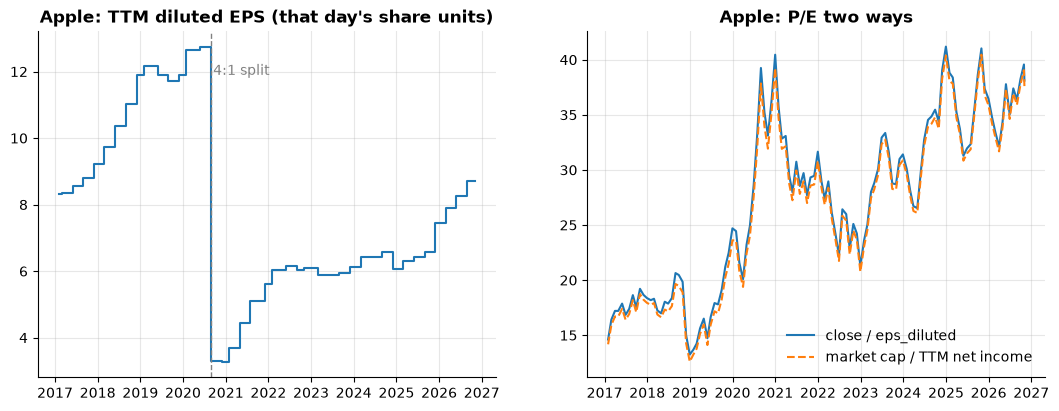

In [14]:
aapl = v.fundamentals(["net_income", "eps_diluted"], start="2017-01-01", tickers="AAPL", ratios=False)
aapl = aapl.with_columns((pl.col("close") / pl.col("eps_diluted")).alias("pe"),
                         (pl.col("issuer_market_cap") / pl.col("net_income")).alias("cap_over_ni"))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.step(aapl["date"], aapl["eps_diluted"], where="post")
ax1.axvline(date(2020, 8, 31), color="grey", ls="--", lw=1)
ax1.text(date(2020, 9, 15), ax1.get_ylim()[1] * 0.9, "4:1 split", color="grey")
ax1.set_title("Apple: TTM diluted EPS (that day's share units)")
ax2.plot(aapl["date"], aapl["pe"], label="close / eps_diluted")
ax2.plot(aapl["date"], aapl["cap_over_ni"], ls="--", label="market cap / TTM net income")
ax2.set_title("Apple: P/E two ways")
ax2.legend()
plt.show()

For ADRs, EPS is per ordinary share in the reporting currency, not per ADS, so close / EPS is
not a P/E there. Use `earnings_yield` (USD reporters) instead.

### Missing is not zero

Meta and Alphabet paid their first dividends in 2024. Before that the item is missing, not
zero, and the same holds for any company that never paid. Because flows are TTM, the item
stays missing until four quarters with a dividend are on file: here, until each 10-K for 2024
arrived in February 2025. Filling with 0 is right for Meta in 2023, but wrong for a company
that reports its dividends under a tag outside the catalogue, so check how a company reports
before treating missing as zero.

In [15]:
(f.filter(pl.col("ticker").is_in(["META", "GOOGL"]) & pl.col("date").is_between(date(2023, 12, 1), date(2025, 6, 30)))
 .select("date", "ticker", (pl.col("dividends_paid") / 1e9).alias("dividends_paid_bn"))
 .pivot(on="ticker", index="date", values="dividends_paid_bn"))

date,META,GOOGL
date,f64,f64
2023-12-29,null,null
2024-01-31,null,null
2024-02-29,null,null
2024-03-28,null,null
2024-04-30,null,null
2024-05-31,null,null
2024-06-28,null,null
2024-07-31,null,null
2024-08-30,null,null


### Reorganizations: the same company under a new security or CIK

Fundamentals follow the CIK, and a holding-company reorganization creates a new one, often
with a new security too. ExxonMobil moved to ExxonMobil Holdings Corp on 1 July 2026. The new
CIK had no share count until its first 10-Q and no TTM flows of its own for up to a year.
`v.successors()` links the two. Until the successor has its own figures, the predecessor's
share count, float and fundamentals carry it, so XOM keeps its market cap, rank and P/E.

In [16]:
xom = v.successors().filter(pl.col("ticker") == "XOM")
print(xom.select("predecessor_id", "security_id", "predecessor_cik", "cik", "link_date", "kind", "price_ratio", "evidence"))
(v.fundamentals(["revenue", "net_income", "assets", "eps_diluted"], start="2026-04-01", tickers="XOM", ratios=False)
 .select("date", "security_id", "cik", (pl.col("revenue") / 1e9).alias("revenue_bn"),
         (pl.col("net_income") / 1e9).alias("net_income_bn"), (pl.col("assets") / 1e9).alias("assets_bn"),
         "eps_diluted"))

shape: (1, 8)
┌────────────────┬──────────────┬─────────────────┬────────────┬────────────┬──────────┬─────────────┬──────────┐
│ predecessor_id ┆ security_id  ┆ predecessor_cik ┆ cik        ┆ link_date  ┆ kind     ┆ price_ratio ┆ evidence │
│ ---            ┆ ---          ┆ ---             ┆ ---        ┆ ---        ┆ ---      ┆ ---         ┆ ---      │
│ str            ┆ str          ┆ str             ┆ str        ┆ date       ┆ str      ┆ f64         ┆ str      │
╞════════════════╪══════════════╪═════════════════╪════════════╪════════════╪══════════╪═════════════╪══════════╡
│ BBG000GZQ728   ┆ BBG023CY9MM1 ┆ 0000034088      ┆ 0002115436 ┆ 2026-07-02 ┆ security ┆ 1.002706    ┆ name     │
└────────────────┴──────────────┴─────────────────┴────────────┴────────────┴──────────┴─────────────┴──────────┘


date,security_id,cik,revenue_bn,net_income_bn,assets_bn,eps_diluted
date,str,str,f64,f64,f64,f64
2026-04-30,"""BBG000GZQ728""","""0000034088""",332.238,28.844,448.98,6.7
2026-05-29,"""BBG000GZQ728""","""0000034088""",334.246,25.314,464.41,5.94
2026-06-30,"""BBG000GZQ728""","""0000034088""",334.246,25.314,464.41,5.94
2026-07-31,"""BBG023CY9MM1""","""0002115436""",334.246,25.314,464.41,5.94
2026-08-31,"""BBG023CY9MM1""","""0002115436""",334.246,25.314,464.482,5.94
2026-09-30,"""BBG023CY9MM1""","""0002115436""",334.246,25.314,464.482,5.94
2026-10-30,"""BBG023CY9MM1""","""0002115436""",334.246,25.314,464.482,5.94
2026-11-03,"""BBG023CY9MM1""","""0002115436""",334.246,25.314,470.917,5.94


The successors table also lists same-security CIK changes (Alphabet in 2016, Broadcom). A
return series keyed by `security_id` stops at a `security` handoff: link it through
`successors()` (`price_ratio` is the first new close over the last old one, about 1).

### Other things to keep in mind

- **Industry definitions differ**: bank "revenue" is net revenue or interest income, REITs'
  is lease income, insurers' is earned premiums (the fallback tags in the catalogue). Compare
  within an industry, or prefer items that mean the same everywhere (net income, equity).
- **Per security, not per company**: with `primary_only=False`, every class of a multi-class
  company (GOOG and GOOGL) gets the same company numbers. The default keeps one row per company.
- **Tickers are resolved per security**: `tickers="META", by="security"` follows Meta across its
  FB years; `by="ticker"` returns whatever traded under the symbol (the security master
  notebook, `massive-subspace-stream/06_identity.ipynb`, explains).
- **History starts with XBRL**: 2009 for large filers, 2011 for everyone, later for many
  foreign filers. Nothing earlier.

## 9 · Coverage of the tradable universe

The security master knows each traded security's CIK on each day. For the common stocks in the
universe on a few dates: does EDGAR know the company, and were revenue and a share count
usable that day?

In [17]:
rows = []
for day in (date(2011, 6, 30), date(2014, 6, 30), date(2018, 6, 29), date(2022, 6, 30), date(2026, 10, 30)):
    u = massive.universe(day, types=["CS"])
    ciks = u["cik"].drop_nulls().unique().to_list()
    known = set(edgar.companies().filter(pl.col("cik").is_in(ciks))["cik"])
    snap = edgar.as_of(day, ciks=ciks, items=["revenue"])
    has_rev = set(snap.filter(pl.col("item") == "revenue")["cik"])
    has_sh = set(snap.filter(pl.col("item") == "shares")["cik"])
    rows.append((day, u.height, len(ciks), len(known), len(has_rev), len(has_sh)))
cov = pl.DataFrame(rows, schema=["day", "common_stocks", "with_cik", "in_edgar", "revenue_usable", "shares_usable"], orient="row")
cov.with_columns(*[(pl.col(c) / pl.col("with_cik") * 100).round(1).alias(f"{c}_pct") for c in ("in_edgar", "revenue_usable", "shares_usable")])

day,common_stocks,with_cik,in_edgar,revenue_usable,shares_usable,in_edgar_pct,revenue_usable_pct,shares_usable_pct
date,i64,i64,i64,i64,i64,f64,f64,f64
2011-06-30,4575,4403,3771,1255,1350,85.6,28.5,30.7
2014-06-30,5026,4853,4326,3379,3632,89.1,69.6,74.8
2018-06-29,4533,4420,4327,3793,4033,97.9,85.8,91.2
2022-06-30,5748,5647,5621,4556,4952,99.5,80.7,87.7
2026-10-30,5163,5046,5017,4243,4625,99.4,84.1,91.7


What is missing, and why:
- **2011**: small companies only started XBRL with periods after mid-2011.
- **Foreign filers** (20-F/40-F) started XBRL with fiscal 2014-2015, which holds back 2014.
- **Closed-end funds and BDCs** (typed as common stock by Massive) filed no XBRL statements
  for most of this history.
- **No revenue line**: shells, SPACs and early-stage biotechs; some banks and insurers use tags
  outside the map.
- Annual-only filers drop out once their last fiscal year is more than 400 days old.

## 10 · Cross-check against Massive's financials

For the largest current common stocks, compare Massive's quarterly revenue with EDGAR's
first-filed value for the same quarter, and Massive's `filing_date` with the original filing.

15,488 company-quarters from 290 companies
same revenue (within 0.5%): 86.3%
Massive's filing_date later than the original filing: 90.6% (median lag when late: 365 days)


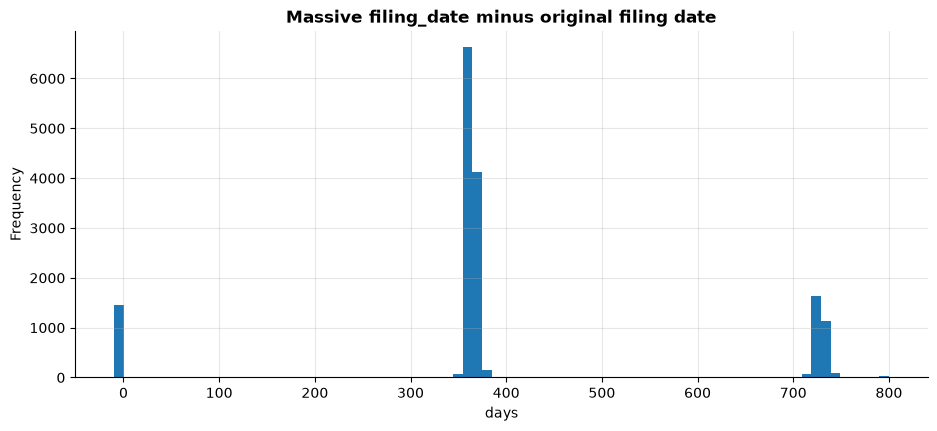

In [18]:
u = massive.universe(date(2026, 10, 30), types=["CS"]).with_columns((pl.col("close") * pl.col("volume")).alias("dv"))
top = u.sort("dv", descending=True).head(300).filter(pl.col("cik").is_not_null())
m = (massive.financials("income").filter(pl.col("timeframe") == "quarterly", pl.col("cik").is_in(top["cik"].to_list()))
     .select("cik", pl.col("period_end").alias("end"), pl.col("revenue").alias("massive_revenue"),
             pl.col("filing_date").alias("massive_filing_date")))
e = edgar.series("revenue", ciks=top["cik"].to_list()).filter(pl.col("period") == "quarter").select(
    "cik", "end", pl.col("value").alias("edgar_revenue"), pl.col("filed").alias("edgar_first_filed"))
cmp = m.join(e, on=["cik", "end"]).filter(pl.col("massive_revenue").is_not_null() & (pl.col("edgar_revenue") != 0))
cmp = cmp.with_columns(
    ((pl.col("massive_revenue") / pl.col("edgar_revenue") - 1).abs() < 0.005).alias("same_value"),
    (pl.col("massive_filing_date") - pl.col("edgar_first_filed")).dt.total_days().alias("massive_date_lag_days"))
print(f"{cmp.height:,} company-quarters from {cmp['cik'].n_unique()} companies")
print(f"same revenue (within 0.5%): {cmp['same_value'].mean() * 100:.1f}%")
print(f"Massive's filing_date later than the original filing: {(cmp['massive_date_lag_days'] > 0).mean() * 100:.1f}% "
      f"(median lag when late: {cmp.filter(pl.col('massive_date_lag_days') > 0)['massive_date_lag_days'].median():.0f} days)")
ax = cmp["massive_date_lag_days"].clip(-10, 800).to_pandas().plot.hist(bins=80, title="Massive filing_date minus original filing date")
ax.set_xlabel("days");

The values mostly agree; the dates do not. Massive dates most older quarters by a filing a
year or two later (the spikes near 365 and 730 days), which is why everything downstream takes
fundamentals from EDGAR through this package.